In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
from google.colab import files
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

In [4]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)

image_files = [f for f in os.listdir('images') if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
print(f"\nUploaded {len(image_files)} Image(s).")

Saving Tiger_Woods.png to Tiger_Woods.png
Saving volleyball.jpg to volleyball.jpg

Uploaded 2 Image(s).


Loading Pose Landmarker Model...


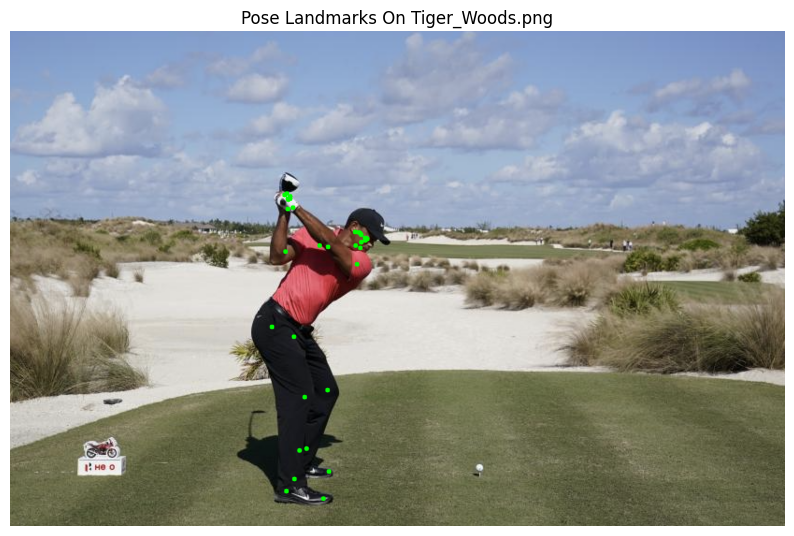

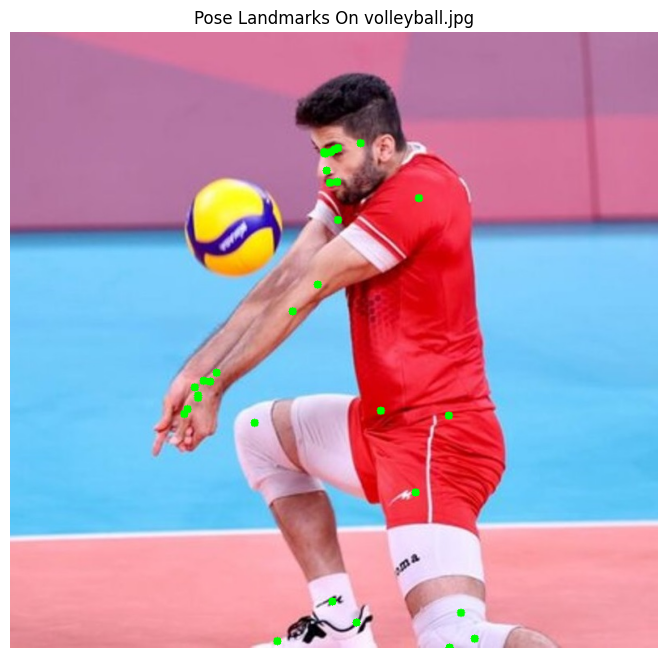

In [8]:
model_url = 'https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task'
local_model_path = 'pose_landmarker_lite.task'

if not os.path.exists(local_model_path):
    print("Downloading Pose Landmarker Model...")
    urllib.request.urlretrieve(model_url, local_model_path)

print("Loading Pose Landmarker Model...")
base_options = python.BaseOptions(model_asset_path=local_model_path)
options = vision.PoseLandmarkerOptions(base_options=base_options, running_mode=vision.RunningMode.IMAGE)

with vision.PoseLandmarker.create_from_options(options) as landmarker:
  for img_file in image_files:
    img_path = os.path.join('images', img_file)
    img = cv2.imread(img_path)
    if img is None:
      continue

    image_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)

    result = landmarker.detect(mp_image)

    if result.pose_landmarks:
      for landmarks in result.pose_landmarks:
        for landmark in landmarks:
          x = int(landmark.x * img.shape[1])
          y = int(landmark.y * img.shape[0])
          cv2.circle(img, (x, y), 5, (0, 255, 0), -1)

    plt.figure(figsize=(10, 8))

    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Pose Landmarks On {img_file}")
    plt.axis('off')

    plt.show()

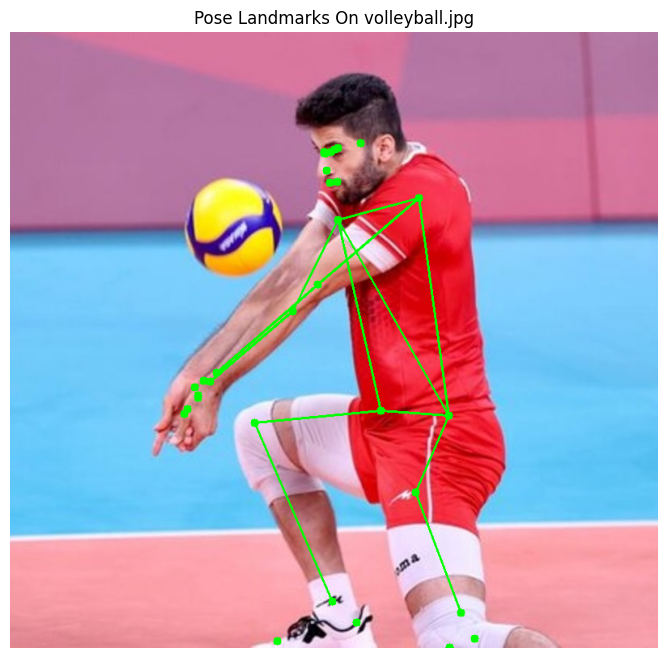

In [10]:
if result.pose_landmarks:
  for landmarks in result.pose_landmarks:
    for landmark in landmarks:
      x = int(landmark.x * img.shape[1])
      y = int(landmark.y * img.shape[0])
      cv2.circle(img, (x, y), 5, (0, 255, 0), -1)

    connections = [
        (11, 12), (11, 13), (13, 15), (12, 14), (14, 16),
        (11, 23), (12, 23), (23, 24), (24, 12),
        (23, 25), (25, 27), (24, 26), (26, 28)
    ]

    for start_idx, end_idx in connections:
      if start_idx < len(landmarks) and end_idx < len(landmarks):
        start = (int(landmarks[start_idx].x * img.shape[1]), int(landmarks[start_idx].y * img.shape[0]))
        end = (int(landmarks[end_idx].x * img.shape[1]), int(landmarks[end_idx].y * img.shape[0]))
        cv2.line(img, start, end, (0, 255, 0), 2)

plt.figure(figsize=(10, 8))

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Pose Landmarks On {img_file}")
plt.axis('off')

plt.show()